In [1]:
import geopandas as gpd
import numpy as np
import pandas as pd
from pathlib import Path
import scanpy as sc
import scipy.sparse as sp
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.loader import NeighborLoader
from torch_geometric.nn import SAGEConv

/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound
/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


#### Variables, Files, Paths
##### Variables 
- `sample`: String. Defines the sample we are working from. E.g.: Colorectal_Cancer_Person_2 (CRC_P2)
- `bin_size`: String. Choose between 2um, 8um and 16um for Visium Outputs. Not necessary for Xenium - _select default somehow_?
- `xpca_hist`: Bool. Has PCA been performed on histology embeddings yet?
- `xpca_trans`: Bool. Has PCA been performed on transcriptomics embeddings yet?
- `xpca_col_hist`: String. Column that stores PCA embeddings for histology
- `xpca_col_trans`: String. Column that stores PCA embeddings for transcriptomics
- `loss_fct`: String. Loss function to apply to autoencoders 

##### Paths
- `basedir`: String. Base directory where all data is stored
- `dir_histology`: String. Directory where all histological information is stored. Can be per person or for all people combined (in this case: "combined" folder)
- `dir_transcriptomics`: String. Directory where all transcriptomics information is stored. Can be per person or for all people combined (in this case: "combined" folder)
- `dir_output`: String. Output directory autoencoder results.

##### Files and filenames
- `f_hist_adata`: h5ad. Contains histology information such as Slide_ID (=sample), column per patch with ID and embeddings, x any coord, gene counts, PCA, etc
- `f_trans_adata`: h5ad. Contains transcriptomics information such as Slide_ID (=sample), column per bin or cell with ID and embeddings, assigned Patch ID, genes, etc.
- `f_trans_coord`: parquet. For each cell/nucleus stores: ID, geomtetry, centroid, inner centroid, etc.

In [ ]:
# Variables
sample = "combined"
bin_size = "002um"
dir_cellseg = "cell_seg_stardist" # in case of multiple cell segmentation methods, this determines which method we work with
# xpca_hist = False    # checks if PCA has been performed yet
# xpca_trans = False    # checks if PCA has been performed yet
# xpca_col_hist = "X_pca"   # choose different name if PCA are stored under a different column name 
# xpca_col_trans = "X_pca"   # choose different name if PCA are stored under a different column name 
# loss_fct = "ntxent" # optional loss functions: ntxent, cosine


# Paths/Directories
basedir = Path("../../data")
dir_hist = basedir / "combined/01_preprocessing/unimodel/metadata"                               # Note: these directories refer to the combined folder. 
dir_trans = basedir / "combined/01_preprocessing" / dir_cellseg / bin_size / "custom_binning" # If you want to access a single slide folder, please define an extra path. 
dir_output = basedir / sample / "03_integration/autoencoders" / bin_size
dir_output.mkdir(parents=True, exist_ok=True)

# Files and filenames
f_hist_adata = sc.read_h5ad(dir_hist / "filtered_WSI_patch_embeddings.h5ad")
f_trans_adata = sc.read_h5ad(dir_trans / "count_area_filtered_adata.h5ad")
f_trans_coord = gpd.read_parquet(dir_trans / "nuclei_geometry.parquet")

## Filter adata for single sample
# f_hist_adata = f_hist_adata[f_hist_adata.obs["Slide_ID"] == sample]
# f_trans_adata = f_trans_adata[f_trans_adata.obs["Slide_ID"] == sample]
# f_trans_coord = f_trans_coord[f_trans_coord["Slide_ID"] == sample]

# Re-set indices
# Do not run this section(s) if 
#   1. f_trans_adata.index is already equal to the actual cell id and/or
#   2. f_hist_adata.index is already equal to the Patch_ID
if not f_trans_adata.obs["id"].is_unique:   # 1.
    raise ValueError(f"Cannot set 'id' as index: contains duplicates")
f_trans_adata.obs = f_trans_adata.obs.set_index(f_trans_adata.obs["id"].astype(str))

if not f_hist_adata.obs["Patch_ID"].is_unique:   # 2.
    raise ValueError(f"Cannot set 'Patch_ID' as index: contains duplicates")
f_hist_adata.obs = f_hist_adata.obs.set_index(f_hist_adata.obs["Patch_ID"].astype(str))
f_trans_adata

# Get embedding sizes
hist_obs, hist_features  = f_hist_adata.shape
trans_obs, trans_features = f_trans_adata.shape
print('--- Histology ---')
print("Observation (patch) count histology data: ", hist_obs, " with feature vector length ", hist_features, ".")
# if xpca_col_hist in f_hist_adata.obsm.keys():
#     print("NOTE: PCA has already been performed on histology embeddings. New embedding size: ", f_hist_adata.obsm[xpca_col_hist].shape[1])
#     xpca_hist = True

print('--- Transcriptomics ---')
print("Observation (nuclei/bin) count transcriptomics data: ", trans_obs, " with feature vector length ", trans_features, ".")
# if xpca_col_trans in f_trans_adata.obsm.keys():
#     print("NOTE: PCA has already been performed on transcritpomic embeddings. New embedding size: ", f_trans_adata.obsm[xpca_col_trans].shape[1])
#     xpca_trans = True

# del 
# gc.collect()

/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/aligned_df.py:67: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


--- Histology ---
Observation (patch) count histology data:  9572  with feature vector length  1536 .
NOTE: PCA has already been performed on histology embeddings. New embedding size:  50
--- Transcriptomics ---
Observation (nuclei/bin) count transcriptomics data:  144296  with feature vector length  18085 .
NOTE: PCA has already been performed on transcritpomic embeddings. New embedding size:  50


# The autoencoder

### Transcriptomics setup
Note, that f_trans_adata.X is log-normalised.

In [ ]:
# Functions

# Global SVG union mask over alll samples
def get_svg_union_mask(trans_adata, per_sample_key="spatially_variable_per_sample"):
    """Union across samples: gene is an SVG if flagged in >=1 sample."""
    if per_sample_key in trans_adata.varm:
        sv = np.asarray(trans_adata.varm[per_sample_key]).astype(bool)
        return sv.any(axis=1)
    # fallback: use precomputed n_samples count column
    return (trans_adata.var["spatially_variable_n_samples"] >= 1).values

# spatial neighborhood graph --> represtn nuclei as graph
def build_spatial_graph(trans_adata, library_key="Slide_ID", n_neighs=6):
    """Uses squidpy so that neighbors are only ever formed within a sample."""
    import squidpy as sq
    sq.gr.spatial_neighbors(
        trans_adata,
        library_key=library_key, #Slide_ID --> make sure one grpah per sample, separatee
        coord_type="generic",
        n_neighs=n_neighs,
    )
    conn = trans_adata.obsp["spatial_connectivities"]
    # sanity check: no cross-sample edges
    slide_ids = trans_adata.obs[library_key].values
    coo = conn.tocoo()
    cross = (slide_ids[coo.row] != slide_ids[coo.col]).sum()
    assert cross == 0, f"Found {cross} cross-sample edges - check library_key"
    return conn

# pairs single-nucleus spatial transcriptomics data (here:nuclei) with corresponding histology image patch embeddings
def build_pairing(trans_adata, hist_adata, trans_patch_col="Patch_ID", hist_patch_col="Patch_ID",
                   slide_col="Slide_ID"):
    """
    Returns:
      keep_mask: which nuclei to keep (discard nuclei with no matching patch)
      patch_row_trans: (n_trans,) int array, which histolofy row belongs to which nucleus
      hist_emb: (n_unique_patches, hist_dim) float32 array, one row per unique patch
    """
    trans_key = (
        trans_adata.obs[slide_col].astype(str) + "_" + trans_adata.obs[trans_patch_col].astype(str)
    )
    hist_key = (
        hist_adata.obs[slide_col].astype(str) + "_" + hist_adata.obs[hist_patch_col].astype(str)
    )

    # hist should already be one row per patch; verify uniqueness
    assert hist_key.is_unique, "hist.obs has duplicate Slide_ID+Patch_ID rows"

    key_to_hist_row = {k: i for i, k in enumerate(hist_key)}

    missing = ~trans_key.isin(key_to_hist_row)
    if missing.any():
        print(f"WARNING: {missing.sum()} / {len(trans_key)} nuclei have no matching "
              f"hist patch - dropping them.")
    keep_mask = ~missing.values

    patch_key_trans = trans_key.values[keep_mask]
    patch_row_trans = np.array([key_to_hist_row[k] for k in patch_key_trans])

    hist_X = hist_adata.X
    hist_emb = hist_X.toarray() if sp.issparse(hist_X) else np.asarray(hist_X)
    hist_emb = hist_emb.astype(np.float32)

    return keep_mask, patch_row_trans, hist_emb

# wraps processed transcriptomics, spatial neighborhood graph, and multimodal metadata into single PyG Data object
# Each node stores:  
# - SVG expression
# - graph edges
# - patch index
# - slide code
# The latter two are not used during message passing but are needed during training.
def build_pyg_data(X_svg, conn, patch_row_trans, slide_codes):
    edge_index = torch.tensor(np.vstack(conn.tocoo().nonzero()), dtype=torch.long)
    data = Data(
        x=torch.tensor(X_svg, dtype=torch.float32),
        edge_index=edge_index,
    )
    # stash extra per-node tensors needed downstream (not used in message passing)
    data.patch_row = torch.tensor(patch_row_trans, dtype=torch.long)
    data.slide_code = torch.tensor(slide_codes, dtype=torch.long)
    return data

# neighborhood sampling - scalable spatial Mini-Batching
# scalable so we dont always load and update the entire graph
def make_loader(data, batch_size=512, num_neighbors=(10, 10), shuffle=True):
    return NeighborLoader(
        data,
        num_neighbors=list(num_neighbors),
        batch_size=batch_size,
        shuffle=shuffle,
        input_nodes=None,  # sample from all nodes
    )


# STEP 6: Multi-positive InfoNCE (handles many-nuclei -> one-patch)
# not just one positive pari but one patch corresponds to MANY nuclei
# ALL MATCHING nuclei should be close to the same histology embedding.
def multi_positive_infonce(p_trans, p_hist, patch_row, temperature=0.07):
    """
    p_trans: (B, D) projected+normalized trans embeddings (one per nucleus)
    p_hist:  (B, D) projected+normalized hist embeddings, ALREADY gathered
             per-nucleus (i.e. p_hist[i] = embedding of the patch nucleus i belongs to)
    patch_row: (B,) int, which unique patch each nucleus belongs to
               (used to build the positive mask - nuclei sharing a patch are
               mutual positives, not negatives)
    """
    logits = p_trans @ p_hist.T / temperature  # (B, B)
    patch_row = patch_row.view(-1, 1)
    pos_mask = (patch_row == patch_row.T).float()

    log_prob = logits - torch.logsumexp(logits, dim=1, keepdim=True)
    loss_t2h = -(pos_mask * log_prob).sum(1) / pos_mask.sum(1)

    logits_h2t = logits.T
    log_prob_h2t = logits_h2t - torch.logsumexp(logits_h2t, dim=1, keepdim=True)
    loss_h2t = -(pos_mask * log_prob_h2t).sum(1) / pos_mask.sum(1)

    return 0.5 * (loss_t2h.mean() + loss_h2t.mean())


def train_step(model, batch, hist_emb_all, opt, slide_lookup, contrast_weight,
               device="cuda"):
    model.train()
    opt.zero_grad()

    x = batch.x.to(device)
    edge_index = batch.edge_index.to(device)
    bsz = batch.batch_size  # PyG guarantees seed nodes are the first `batch_size` rows

    z_full = model.trans_enc(x, edge_index)   # (all sampled nodes, latent)
    z_trans = z_full[:bsz]                     # only seed nuclei get recon/contrast loss

    slide_code = batch.slide_code[:bsz].to(device)
    x_recon = model.trans_dec(z_trans, slide_code)
    loss_recon_trans = F.mse_loss(x_recon, x[:bsz])

    patch_row = batch.patch_row[:bsz].to(device)
    hist_batch = hist_emb_all[patch_row].to(device)   # (bsz, hist_dim), per-nucleus lookup

    z_hist = model.hist_enc(hist_batch)
    hist_recon = model.hist_dec(z_hist)
    loss_recon_hist = F.mse_loss(hist_recon, hist_batch)

    p_trans = model.proj_trans(z_trans)
    p_hist = model.proj_hist(z_hist)
    loss_contrast = multi_positive_infonce(p_trans, p_hist, patch_row)

    loss = loss_recon_trans + loss_recon_hist + contrast_weight * loss_contrast
    loss.backward()
    opt.step()

    return {
        "loss": loss.item(),
        "recon_trans": loss_recon_trans.item(),
        "recon_hist": loss_recon_hist.item(),
        "contrast": loss_contrast.item(),
    }


def contrast_weight_schedule(epoch, warmup_epochs=5, max_weight=1.0):
    """Ramp contrastive loss weight up linearly, reconstruction stabilizes first."""
    return max_weight * min(1.0, epoch / warmup_epochs)


def train(model, loader, hist_emb_all, n_epochs=30, lr=1e-3, warmup_epochs=5,
          max_contrast_weight=1.0, device="cuda"):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist_emb_all = hist_emb_all.to(device)

    for epoch in range(n_epochs):
        cw = contrast_weight_schedule(epoch, warmup_epochs, max_contrast_weight)
        epoch_stats = {"loss": 0.0, "recon_trans": 0.0, "recon_hist": 0.0, "contrast": 0.0}
        n_batches = 0
        for batch in loader:
            stats = train_step(model, batch, hist_emb_all, opt, None, cw, device)
            for k in epoch_stats:
                epoch_stats[k] += stats[k]
            n_batches += 1
        epoch_stats = {k: v / n_batches for k, v in epoch_stats.items()}
        print(f"epoch {epoch:03d} | contrast_w={cw:.2f} | " +
              " | ".join(f"{k}={v:.4f}" for k, v in epoch_stats.items()))
        

@torch.no_grad()
def retrieval_accuracy(model, data, hist_emb_all, sample_size=2000, device="cuda"):
    """For a random sample of nuclei, check if the correct patch is the
    nearest neighbor among a pool of candidate patch embeddings."""
    model.eval()
    idx = np.random.choice(data.num_nodes, size=sample_size, replace=False)
    x = data.x[idx].to(device)
    edge_index = data.edge_index.to(device)  # note: for a rigorous check, use full-graph
    # NB: for large graphs, run this via the same NeighborLoader mechanism instead
    z_trans_full = model.trans_enc(data.x.to(device), edge_index)
    z_trans = z_trans_full[idx]
    p_trans = model.proj_trans(z_trans)

    unique_patches = torch.unique(data.patch_row)
    hist_batch = hist_emb_all[unique_patches].to(device)
    z_hist = model.hist_enc(hist_batch)
    p_hist = model.proj_hist(z_hist)

    sims = p_trans @ p_hist.T
    pred = sims.argmax(dim=1)
    true_patch = data.patch_row[idx].to(device)
    patch_to_col = {p.item(): i for i, p in enumerate(unique_patches)}
    true_col = torch.tensor([patch_to_col[p.item()] for p in true_patch], device=device)

    acc = (pred == true_col).float().mean().item()
    print(f"Top-1 patch retrieval accuracy: {acc:.3f} (chance = {1/len(unique_patches):.5f})")
    return acc

In [ ]:
# Model defintions

######## TRANSCRIPOTMICS
# Traanscriptomics Encoder
# Idea: SVGs --> GraphSAGE --> GraphSAGE --> Linear Layer --> latent vector
# note: nucleus representation depends on nearby nuclei
class SVGGraphEncoder(nn.Module):
    """GraphSAGE encoder for SVG features + spatial neighborhood context."""
    def __init__(self, in_dim, hidden_dim=256, latent_dim=64, n_slides=5, dropout=0.1):
        super().__init__()
        self.conv1 = SAGEConv(in_dim, hidden_dim)
        self.conv2 = SAGEConv(hidden_dim, hidden_dim)
        self.bn1 = nn.BatchNorm1d(hidden_dim)
        self.bn2 = nn.BatchNorm1d(hidden_dim)
        self.dropout = dropout
        self.out = nn.Linear(hidden_dim, latent_dim)

    def forward(self, x, edge_index):
        h = F.relu(self.bn1(self.conv1(x, edge_index)))
        h = F.dropout(h, p=self.dropout, training=self.training)
        h = F.relu(self.bn2(self.conv2(h, edge_index)))
        z = self.out(h)
        return z
    
 # Transcriptomics + Histology Decoder  
 # Uses Slide_ID one-hot encoding --> conditions encoder on orignal sample (make latent space more sample-independent) 
class MLPDecoder(nn.Module):
    def __init__(self, latent_dim, hidden_dims, out_dim, n_slides=5, condition_on_slide=True):
        super().__init__()
        self.condition_on_slide = condition_on_slide
        in_dim = latent_dim + (n_slides if condition_on_slide else 0)
        layers, d = [], in_dim
        for h in hidden_dims:
            layers += [nn.Linear(d, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(0.1)]
            d = h
        layers.append(nn.Linear(d, out_dim))
        self.net = nn.Sequential(*layers)
        self.n_slides = n_slides

    def forward(self, z, slide_code=None):
        if self.condition_on_slide:
            onehot = F.one_hot(slide_code, num_classes=self.n_slides).float()
            z = torch.cat([z, onehot], dim=-1)
        return self.net(z)



################### HISTOLOGY
# Hist Encoder : MLP (patch embedding -> latent vector)
# Note: NOT conditioned on SLIDE_ID
# Note DECODER: MLP, uses class above
class MLPEncoder(nn.Module):
    def __init__(self, in_dim, hidden_dims, latent_dim, dropout=0.1):
        super().__init__()
        layers, d = [], in_dim
        for h in hidden_dims:
            layers += [nn.Linear(d, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
            d = h
        layers.append(nn.Linear(d, latent_dim))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

# Idea: learn latent z -> projection p 
# Autoencoder reconstructs from z
# contrastive larning operates on p
class ProjectionHead(nn.Module):
    """Separate small head for contrastive space, keeps z_recon space free."""
    def __init__(self, latent_dim, proj_dim=32):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, latent_dim), nn.ReLU(),
            nn.Linear(latent_dim, proj_dim)
        )

    def forward(self, z):
        return F.normalize(self.net(z), dim=-1)
    
################ AUTOENC
class DualAutoencoder(nn.Module):
    def __init__(self, n_svg, hist_dim, latent_dim=64, proj_dim=32, n_slides=5):
        super().__init__()
        self.trans_enc = SVGGraphEncoder(n_svg, 256, latent_dim, n_slides)
        self.trans_dec = MLPDecoder(latent_dim, [256, 512], n_svg, n_slides)
        self.hist_enc = MLPEncoder(hist_dim, [512, 128], latent_dim)
        self.hist_dec = MLPDecoder(latent_dim, [128, 512], hist_dim, n_slides,
                                    condition_on_slide=False)
        self.proj_trans = ProjectionHead(latent_dim, proj_dim)
        self.proj_hist = ProjectionHead(latent_dim, proj_dim)


In [ ]:
import anndata as ad
import torch

# set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# get files
trans_adata = ad.read_h5ad(dir_trans / "count_area_filtered_adata.h5ad")
hist_adata = ad.read_h5ad(dir_hist / "filtered_WSI_patch_embeddings.h5ad")
f_trans_coord = gpd.read_parquet(dir_trans / "nuclei_geometry.parquet")

# 1. SVG mask
svg_mask = get_svg_union_mask(trans_adata)
print(f"{svg_mask.sum()} SVGs selected (union)")

# 2. spatial graph
conn = build_spatial_graph(trans_adata, library_key="Slide_ID", n_neighs=6)

# 3. pairing
keep_mask, patch_row_trans, hist_emb = build_pairing(trans_adata, hist_adata)

# subset trans + graph consistently to keep_mask
trans_sub = trans_adata[keep_mask].copy()
conn_sub = conn[keep_mask][:, keep_mask]  # keep only kept nuclei's edges
X_svg = trans_sub.X[:, svg_mask]
X_svg = X_svg.toarray() if sp.issparse(X_svg) else np.asarray(X_svg)

slide_codes, slide_uniques = pd.factorize(trans_sub.obs["Slide_ID"])
n_slides = len(slide_uniques)

# 4. PyG data + loader
data = build_pyg_data(X_svg, conn_sub, patch_row_trans, slide_codes)
loader = make_loader(data, batch_size=512, num_neighbors=(10, 10))

# 5-8. model + training
model = DualAutoencoder(n_svg=X_svg.shape[1], hist_dim=hist_emb.shape[1],
                            latent_dim=64, proj_dim=32, n_slides=n_slides)
hist_emb_t = torch.tensor(hist_emb, dtype=torch.float32)

train(model, loader, hist_emb_t, n_epochs=30, lr=1e-3, warmup_epochs=5,
        device="cuda" if torch.cuda.is_available() else "cpu")

# 9. eval
retrieval_accuracy(model, data, hist_emb_t,
                    device="cuda" if torch.cuda.is_available() else "cpu")

# 10. save model
#torch.save(model.state_dict(), "dual_autoencoder.pt")

/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/anndata/_core/aligned_df.py:67: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


365 SVGs selected (union)
epoch 000 | contrast_w=0.00 | loss=0.0874 | recon_trans=0.0271 | recon_hist=0.0603 | contrast=7.3987
epoch 001 | contrast_w=0.20 | loss=0.5629 | recon_trans=0.0265 | recon_hist=0.0559 | contrast=2.4025
epoch 002 | contrast_w=0.40 | loss=0.7216 | recon_trans=0.0263 | recon_hist=0.0549 | contrast=1.6009
epoch 003 | contrast_w=0.60 | loss=0.8489 | recon_trans=0.0271 | recon_hist=0.0550 | contrast=1.2780
epoch 004 | contrast_w=0.80 | loss=0.9567 | recon_trans=0.0277 | recon_hist=0.0552 | contrast=1.0923
epoch 005 | contrast_w=1.00 | loss=1.0547 | recon_trans=0.0282 | recon_hist=0.0554 | contrast=0.9711
epoch 006 | contrast_w=1.00 | loss=0.9504 | recon_trans=0.0285 | recon_hist=0.0554 | contrast=0.8665
epoch 007 | contrast_w=1.00 | loss=0.8850 | recon_trans=0.0287 | recon_hist=0.0554 | contrast=0.8009
epoch 008 | contrast_w=1.00 | loss=0.8382 | recon_trans=0.0289 | recon_hist=0.0554 | contrast=0.7539
epoch 009 | contrast_w=1.00 | loss=0.8002 | recon_trans=0.0290 | 

0.5090000033378601

After training, the model contains
- model.trans_enc and model.trans_dec
- model.hist_enc and model.hist_dec
- model.proj_trans and model.proj_hist

### Obtaining the embeddings


### Store and load the model and embeddings

**Saving**

In [7]:
# savng model adn state
import torch

torch.save({
    "model_state_dict": model.state_dict(),
    "epoch": 29,  # whatever your last completed epoch was, e.g. 29
    "n_svg": X_svg.shape[1],
    "hist_dim": hist_emb.shape[1],
    "latent_dim": 64,
    "proj_dim": 32,
    "n_slides": n_slides,
}, "outputs/dual_ae_checkpoint.pt")


In [8]:
# save latent embeddings
import numpy as np

with torch.no_grad():
    z_trans_all = model.trans_enc(data.x.to(device), data.edge_index.to(device)).cpu().numpy()
    z_hist_all = model.hist_enc(hist_emb_t.to(device)).cpu().numpy()

np.savez(
    "outputs/dual_ae_latents.npz",
    z_trans=z_trans_all,                                  # per-nucleus trans latent
    z_hist_per_nucleus=z_hist_all[data.patch_row.numpy()], # per-nucleus, via patch lookup
    z_hist_unique=z_hist_all,                              # per-patch, deduplicated
    patch_row=data.patch_row.numpy(),                      # nucleus -> patch index mapping
    slide_code=data.slide_code.numpy(),
)

In [17]:
# save anndata
trans_sub.obsm["X_dae_trans"] = z_trans_all
trans_sub.obsm["X_dae_hist"] = z_hist_all[data.patch_row.numpy()]
trans_sub.obsm["X_dae_joint"] = np.concatenate(
    [trans_sub.obsm["X_dae_trans"], trans_sub.obsm["X_dae_hist"]], axis=1
)

trans_sub.obs = trans_sub.obs.drop(columns=["dae_leiden_0.1", "dae_leiden_0.5"])

trans_sub.write_h5ad("outputs/trans_with_dae_latents.h5ad")

**Loading**

In [ ]:
# Loading model and checkpoints
ckpt = torch.load("outputs/dual_ae_checkpoint.pt")
model = DualAutoencoder(n_svg=ckpt["n_svg"], hist_dim=ckpt["hist_dim"],
                         latent_dim=ckpt["latent_dim"], proj_dim=ckpt["proj_dim"],
                         n_slides=ckpt["n_slides"])
model.load_state_dict(ckpt["model_state_dict"])

# Load latents
data = np.load("outputs/dual_ae_latents.npz")
# print(data.files)
z_trans = data["z_trans"]
z_hist_per_nucleus = data["z_hist_per_nucleus"]
z_hist_unique = data["z_hist_unique"]
patch_row = data["patch_row"]
slide_code = data["slide_code"]

# Load h5ad
trans_sub = sc.read_h5ad("outputs/trans_with_dae_latents.h5ad")

random testing

2026-07-16 12:26:27.962144: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-07-16 12:26:28.089762: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/sklearn/manifold/_spectral_embedding.py:301: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


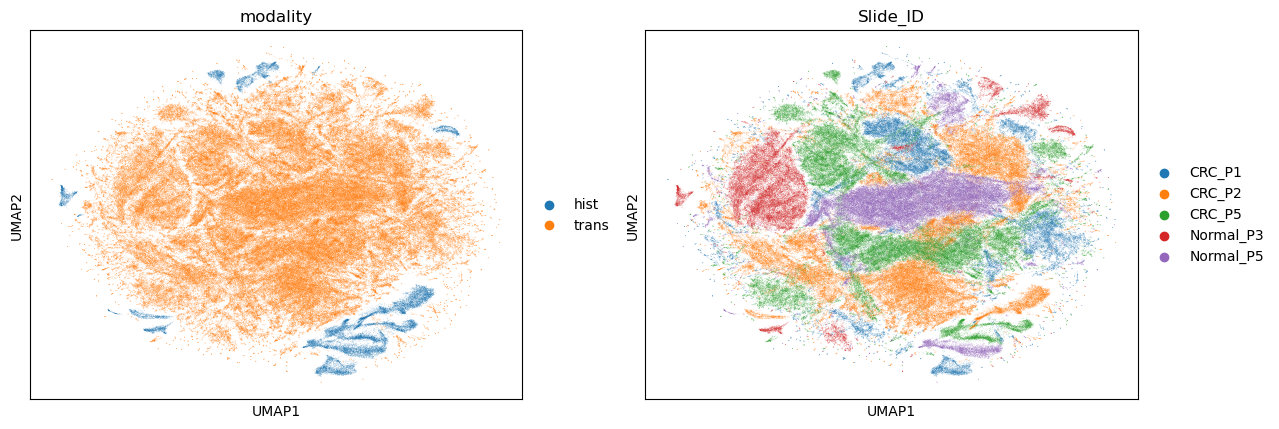

In [9]:
import scanpy as sc
import anndata as ad

with torch.no_grad():
    z_trans_all = model.trans_enc(data.x.to(device), data.edge_index.to(device)).cpu().numpy()
    z_hist_all = model.hist_enc(hist_emb_t.to(device)).cpu().numpy()

# build a combined AnnData: trans latents + hist latents (one row per unique patch,
# duplicated per nucleus so both live in the same embedding space for plotting)
combined = ad.AnnData(
    X=np.vstack([z_trans_all, z_hist_all[np.unique(data.patch_row.numpy())]]),
)
combined.obs["modality"] = (["trans"] * len(z_trans_all) +
                             ["hist"] * len(np.unique(data.patch_row.numpy())))
combined.obs["Slide_ID"] = list(trans_sub.obs["Slide_ID"]) + \
                            list(hist_adata.obs["Slide_ID"].iloc[np.unique(data.patch_row.numpy())])

sc.pp.neighbors(combined, use_rep="X")
sc.tl.umap(combined)
sc.pl.umap(combined, color=["modality", "Slide_ID"])

/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/sklearn/manifold/_spectral_embedding.py:301: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


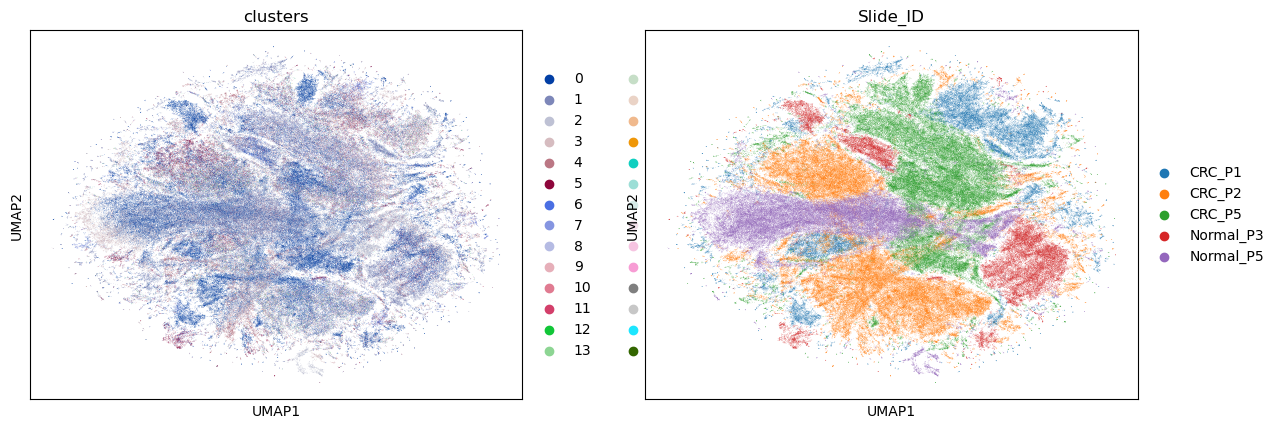

In [ ]:
# Trans latent alone, colored by existing biology and by sample
trans_sub.obsm["X_dae"] = z_trans_all
sc.pp.neighbors(trans_sub, use_rep="X_dae")
sc.tl.umap(trans_sub)
sc.pl.umap(trans_sub, color=["clusters", "Slide_ID"])

In [24]:
# extract latent embeddings
trans_sub.obsm["X_dae_trans"] = z_trans_all
trans_sub.obsm["X_dae_hist"]  = z_hist_all[data.patch_row.numpy()]  # per-nucleus, via patch lookup
trans_sub.obsm["X_dae_joint"] = np.concatenate(
    [trans_sub.obsm["X_dae_trans"], trans_sub.obsm["X_dae_hist"]], axis=1
)

In [ ]:
import harmonypy
import numpy as np

X_input = np.asarray(trans_sub.obsm["X_dae_joint"], dtype=np.float64)
print("input shape:", X_input.shape)  # should be (456562, 128)

ho = harmonypy.run_harmony(X_input, trans_sub.obs, ["Slide_ID"])

Z = np.asarray(ho.Z_corr)          # force plain ndarray, strip matrix type
print("Z_corr shape:", Z.shape)     # check BEFORE transposing — should be (128, 456562)


assert Z.shape[0] == trans_sub.n_obs, f"mismatch: {Z.shape} vs {trans_sub.n_obs} cells"
trans_sub.obsm["X_dae_harmony"] = Z

2026-07-16 15:13:31,374 - harmonypy - INFO - Running Harmony
INFO:harmonypy:Running Harmony
2026-07-16 15:13:31,376 - harmonypy - INFO -   Parameters:
INFO:harmonypy:  Parameters:
2026-07-16 15:13:31,377 - harmonypy - INFO -     max_iter_harmony: 10
INFO:harmonypy:    max_iter_harmony: 10
2026-07-16 15:13:31,378 - harmonypy - INFO -     max_iter_kmeans: 4
INFO:harmonypy:    max_iter_kmeans: 4
2026-07-16 15:13:31,378 - harmonypy - INFO -     epsilon_cluster: 0.001
INFO:harmonypy:    epsilon_cluster: 0.001
2026-07-16 15:13:31,379 - harmonypy - INFO -     epsilon_harmony: 0.01
INFO:harmonypy:    epsilon_harmony: 0.01
2026-07-16 15:13:31,380 - harmonypy - INFO -     nclust: 100
INFO:harmonypy:    nclust: 100
2026-07-16 15:13:31,381 - harmonypy - INFO -     block_size: 0.05


input shape: (456562, 128)


INFO:harmonypy:    block_size: 0.05
2026-07-16 15:13:31,383 - harmonypy - INFO -     lamb: dynamic (alpha=0.2)
INFO:harmonypy:    lamb: dynamic (alpha=0.2)
2026-07-16 15:13:31,385 - harmonypy - INFO -     theta: [2. 2. 2. 2. 2.]
INFO:harmonypy:    theta: [2. 2. 2. 2. 2.]
2026-07-16 15:13:31,386 - harmonypy - INFO -     sigma: [0.1 0.1 0.1 0.1 0.1]...
INFO:harmonypy:    sigma: [0.1 0.1 0.1 0.1 0.1]...
2026-07-16 15:13:31,389 - harmonypy - INFO -     verbose: True
INFO:harmonypy:    verbose: True
2026-07-16 15:13:31,390 - harmonypy - INFO -     random_state: 0
INFO:harmonypy:    random_state: 0
2026-07-16 15:13:31,391 - harmonypy - INFO -   Data: 128 PCs × 456562 cells
INFO:harmonypy:  Data: 128 PCs × 456562 cells
2026-07-16 15:13:31,391 - harmonypy - INFO -   Batch variables: ['Slide_ID']
INFO:harmonypy:  Batch variables: ['Slide_ID']
2026-07-16 15:13:35,794 - harmonypy - INFO - Computing initial centroids...
INFO:harmonypy:Computing initial centroids...
2026-07-16 15:14:26,218 - harmon

Z_corr shape: (456562, 128)
after transpose: (128, 456562)


AssertionError: mismatch: (128, 456562) vs 456562 cells

In [22]:
sc.pp.neighbors(trans_sub, use_rep="X_dae_harmony")
sc.tl.leiden(trans_sub, resolution=0.5, key_added="leiden_harmony")

ct = pd.crosstab(trans_sub.obs["leiden_harmony"], trans_sub.obs["Slide_ID"])
print((ct > 0).sum(axis=1).value_counts().sort_index())
print(trans_sub.obs["leiden_harmony"].nunique())

/tmp/ipykernel_91150/1752357436.py:2: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(trans_sub, resolution=0.5, key_added="leiden_harmony")


1    831
2     47
3     29
4     25
5     16
Name: count, dtype: int64
948


In [23]:
import scipy.sparse as sp
n_components, labels = sp.csgraph.connected_components(
    trans_sub.obsp["connectivities"], directed=False
)
print(n_components)
print(pd.Series(labels).value_counts().head(20))

323
0      442694
19        132
46        131
47        117
113       111
94        107
40        106
296       103
77         92
11         90
115        90
281        89
5          88
41         84
209        80
86         80
247        79
200        78
30         77
167        76
Name: count, dtype: int64


/tmp/ipykernel_14745/1473147264.py:1: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(trans_sub, resolution=0.5, key_added="dae_leiden")
/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


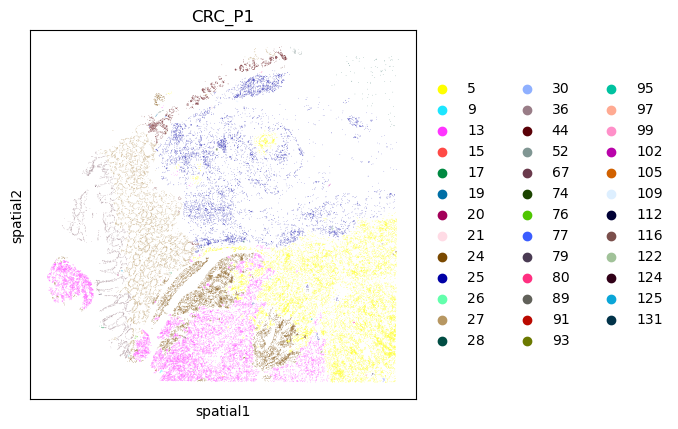

/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


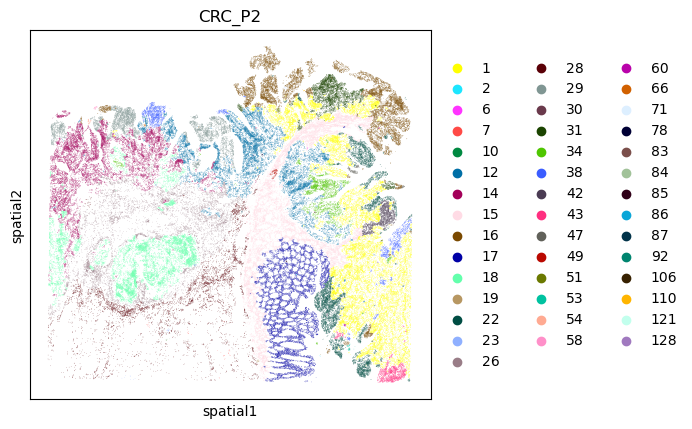

/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


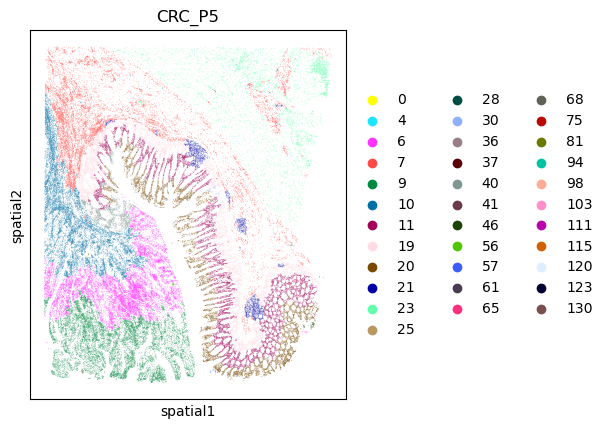

/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


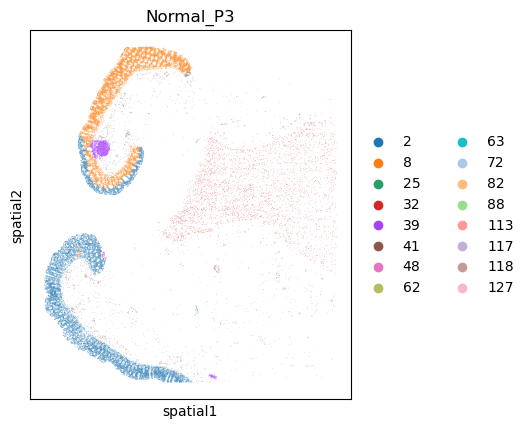

/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/scanpy/plotting/_utils.py:465: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


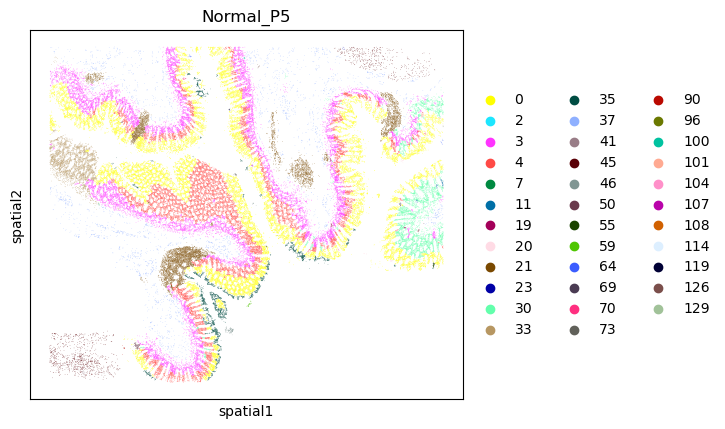

In [11]:
sc.tl.leiden(trans_sub, resolution=0.5, key_added="dae_leiden")

for slide in trans_sub.obs["Slide_ID"].unique():
    sub = trans_sub[trans_sub.obs["Slide_ID"] == slide]
    sc.pl.spatial(sub, color="dae_leiden", spot_size=30, title=slide)

In [12]:
counts = trans_sub.obs["dae_leiden"].value_counts()
print(counts)
print((counts / counts.sum() * 100).round(2))

dae_leiden
0      29271
1      23972
2      21215
3      19957
4      18700
       ...  
121        7
119        7
118        7
117        7
131        6
Name: count, Length: 132, dtype: int64
dae_leiden
0      6.41
1      5.25
2      4.65
3      4.37
4      4.10
       ... 
121    0.00
119    0.00
118    0.00
117    0.00
131    0.00
Name: count, Length: 132, dtype: float64


In [ ]:
import squidpy as sq
for cl in trans_sub.obs["dae_leiden"].cat.categories:
    trans_sub.obs[f"is_{cl}"] = (trans_sub.obs["dae_leiden"] == cl).astype(float)
sq.gr.spatial_autocorr(trans_sub, mode="moran", genes=[f"is_{cl}" for cl in trans_sub.obs["dae_leiden"].cat.categories])

In [19]:
for res in [0.1, 0.2, 0.3, 0.5]:
    sc.tl.leiden(trans_sub, resolution=res, key_added=f"leiden_{res}")
    print(res, trans_sub.obs[f"leiden_{res}"].nunique())
    

0.1 62
0.2 75


/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/scanpy/tools/_leiden.py:199: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  adata.obs[key_added] = pd.Categorical(


0.3 105
0.5 132


/home/charlottewolf/miniconda3/envs/NucleiSeg/lib/python3.11/site-packages/scanpy/tools/_leiden.py:199: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  adata.obs[key_added] = pd.Categorical(


In [20]:
ct = pd.crosstab(trans_sub.obs["leiden_0.5"], trans_sub.obs["Slide_ID"])
n_samples_present = (ct > 0).sum(axis=1)
print(n_samples_present.value_counts().sort_index())
# e.g. output: 1    88   <- present in only 1 sample
#              2    20
#              3    10
#              4     8
#              5     6   <- present in all 5 samples (likely the "real" shared niches)

1    110
2     12
3      8
4      2
Name: count, dtype: int64
